### Background computation
We will use the nuflux package to compute the backgorund emission probability:
$$
n_b(E_i) = \phi_{\nu+\mu}^\text{atm}(E_i)\times A_{eff}\times \Delta T_{obs}
$$

nuflux uses `nu_cos_zenith` as the input angle for the flux. Since IceCube is in the south pole:
$$
\theta_\text{zenith} = 0 \degree \rightarrow \delta = -90\degree
$$
Therefore:
$$
\theta_\text{zenith}(\delta) = \delta + 90 
$$

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import astropy.units as u

import nuflux

In [2]:
def zenith_angle(declination):

    '''Converts declination into zenith angle for IceCube detector '''
    if  not isinstance(declination,  u.Quantity):
        declination = declination * u.deg

    return declination.to(u.deg) + 90 * u.deg 

def cos_zenith(declination):
    
    return np.cos(zenith_angle(declination).to(u.rad))


In [3]:
for dec in np.array([-90, -60, -30, 0, 30, 60, 90]) * u.deg:
    print('dec: ', dec, ' --> IC zenith: ', zenith_angle(dec), ' cos(theta): ',cos_zenith(dec))

dec:  -90.0 deg  --> IC zenith:  0.0 deg  cos(theta):  1.0
dec:  -60.0 deg  --> IC zenith:  30.0 deg  cos(theta):  0.8660254037844387
dec:  -30.0 deg  --> IC zenith:  60.0 deg  cos(theta):  0.5000000000000001
dec:  0.0 deg  --> IC zenith:  90.0 deg  cos(theta):  6.123233995736766e-17
dec:  30.0 deg  --> IC zenith:  120.0 deg  cos(theta):  -0.4999999999999998
dec:  60.0 deg  --> IC zenith:  150.0 deg  cos(theta):  -0.8660254037844387
dec:  90.0 deg  --> IC zenith:  180.0 deg  cos(theta):  -1.0


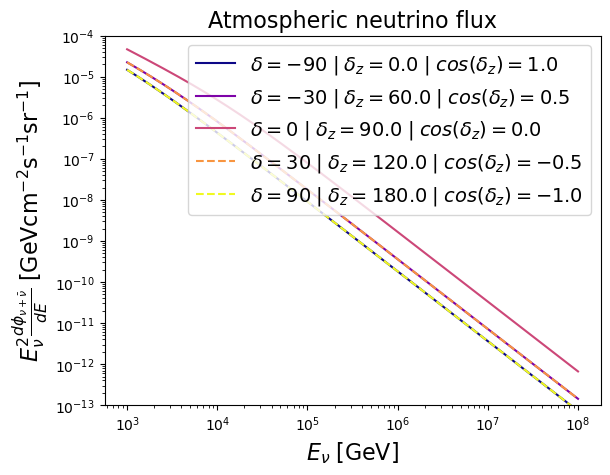

In [4]:

def zenith_angle(declination):

    '''Converts declination into zenith angle for IceCube detector '''
    if  not isinstance(declination,  u.Quantity):
        declination = declination * u.deg

    return declination.to(u.deg) + 90 * u.deg 

def cos_zenith(declination):
    
    return np.cos(zenith_angle(declination).to(u.rad))


flux = nuflux.makeFlux('honda2006')#('CORSIKA_GaisserH3a_average')
nu_type=nuflux.NuMu

dec = 30 * u.deg#degre

# nu_cos_zenith = cos_zenith(50)

E_range = np.logspace(3, 8, 1000)

dec_values = np.array([-90, -30, 0, 30, 90])
cmap = plt.cm.plasma
colors = cmap(np.linspace(0, 1, len(dec_values)))

for dec_i, c, ls in zip(dec_values, colors, ['solid', 'solid', 'solid', 'dashed', 'dashed']):
# for dec_i in np.array([-90, -60, -30]):
    nu_cos_zenith = cos_zenith(dec_i)
    plt.plot(E_range, flux.getFlux(nu_type, E_range, nu_cos_zenith) * E_range **  2, 
             label=rf'$\delta = {dec_i}\;|\;\delta_z={zenith_angle(dec_i).value:.1f}\;|\; cos(\delta_z) = {nu_cos_zenith:.1f}$', linestyle=ls, c=c)
plt.xscale('log')
plt.yscale('log')
plt.xlabel(r'$E_\nu\;[\text{GeV}]$', fontsize=16)
plt.ylabel(r'$E_\nu^2\frac{d\phi_{\nu+\bar \nu}}{dE} \;[\text{GeV}\text{cm}^{-2}\text{s}^{-1}\text{sr}^{-1}]$', fontsize=16)
plt.title("Atmospheric neutrino flux", fontsize=16)
plt.legend(fontsize=14)
plt.ylim(1e-13, 1e-4)
plt.show()



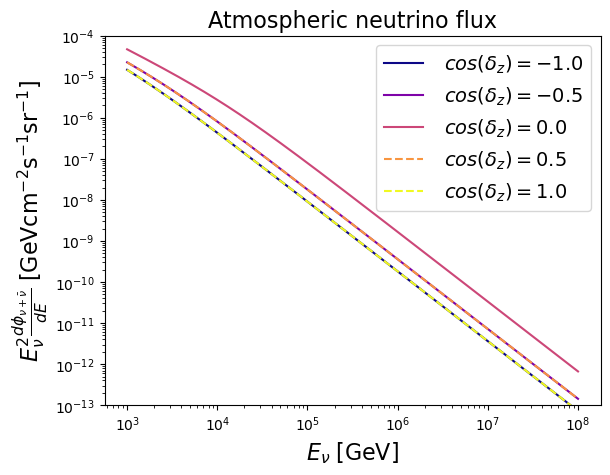

In [5]:
for nu_cos_zenith, c, ls in zip(np.linspace(-1,1,5), colors, ['solid', 'solid', 'solid', 'dashed', 'dashed']):
# for dec_i in np.array([-90, -60, -30]):
    # nu_cos_zenith = cos_zenith(dec_i)
    plt.plot(E_range, flux.getFlux(nu_type, E_range, nu_cos_zenith) * E_range **  2, 
             label=rf'$\; cos(\delta_z) = {nu_cos_zenith:.1f}$', c=c, linestyle=ls)
plt.xscale('log')
plt.yscale('log')
plt.xlabel(r'$E_\nu\;[\text{GeV}]$', fontsize=16)
plt.ylabel(r'$E_\nu^2\frac{d\phi_{\nu+\bar \nu}}{dE} \;[\text{GeV}\text{cm}^{-2}\text{s}^{-1}\text{sr}^{-1}]$', fontsize=16)
plt.title("Atmospheric neutrino flux", fontsize=16)
plt.legend(fontsize=14)
plt.ylim(1e-13, 1e-4)
plt.show()

In [6]:
help(plt.cm)

Help on module matplotlib.cm in matplotlib:

NAME
    matplotlib.cm - Builtin colormaps, colormap handling utilities, and the `ScalarMappable` mixin.

DESCRIPTION
    .. seealso::

      :doc:`/gallery/color/colormap_reference` for a list of builtin colormaps.

      :ref:`colormap-manipulation` for examples of how to make
      colormaps.

      :ref:`colormaps` an in-depth discussion of choosing
      colormaps.

      :ref:`colormapnorms` for more details about data normalization.

CLASSES
    collections.abc.Mapping(collections.abc.Collection)
        ColormapRegistry

    class ColormapRegistry(collections.abc.Mapping)
     |  ColormapRegistry(cmaps)
     |
     |  Container for colormaps that are known to Matplotlib by name.
     |
     |  The universal registry instance is `matplotlib.colormaps`. There should be
     |  no need for users to instantiate `.ColormapRegistry` themselves.
     |
     |  Read access uses a dict-like interface mapping names to `.Colormap`\s::
     |
  